# 3. Evaluation

Loads the models saved by `02_training.ipynb` and evaluates them. All tables are written to `results/` (CSV) and all figures to `results/figures/`.

1. Leakage: random vs. recording-level split
2. Feature study: choosing the features and their parameters
3. Feature set × pooling × model, before and after tuning
4. Comparing the models: how they differ and why
5. Best configuration on the test split, with error analysis
6. Variance over 5 recording-level splits
7. Official IRMAS test set (multi-label)
8. Summary

In [1]:
import sys
from pathlib import Path

project_root = Path.cwd().parent
sys.path.append(str(project_root))

import json
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from IPython.display import display

from src.config import (TRAIN_DATA_DIR, CACHE_DIR, MODELS_DIR, RESULTS_DIR, FIGURES_DIR, SEED, POOLINGS, HOP_LENGTH,
                        FEATURE_SET_NAMES, POOLING_NAMES, WINDOW_SECONDS, HOP_SECONDS, official_test_dirs)
from src.data import load_dataset, load_test_dataset
from src.features import build_features, build_pooled_features, build_window_pooled_features, assemble_features
from src.models import MODEL_NAMES
from src.experiments import MODEL_SLUGS, load_model, predict, predict_proba, get_split, score_models, summarize_repeated
from src.evaluation import (evaluate_model, per_class_metrics, plot_confusion_matrix, plot_loss_curves, top_confusions,
                            family_error_share, aggregate_window_probabilities, evaluate_multilabel, group_permutation_importance)

FIGURES_DIR.mkdir(parents=True, exist_ok=True)

df = load_dataset(TRAIN_DATA_DIR)
manifest = pd.read_csv(MODELS_DIR / "manifest.csv")
split_table = pd.read_csv(MODELS_DIR / "splits.csv")
with open(MODELS_DIR / "feature_specs.json") as f:
    specs = json.load(f)
with open(MODELS_DIR / "best_config.json") as f:
    best_config = json.load(f)

features = build_features(df, specs, POOLINGS, CACHE_DIR, hop_length=HOP_LENGTH)

best_feature_set, best_pooling = best_config["feature_set"], best_config["pooling"]
best_config_name = f"{FEATURE_SET_NAMES[best_feature_set]}, {POOLING_NAMES[best_pooling]}"
train_df, val_df, test_df = get_split(df, split_table, f"grouped_seed{SEED}")

def model_rows(**conditions):
    mask = np.ones(len(manifest), dtype=bool)
    for column, value in conditions.items():
        mask &= manifest[column] == value
    return manifest[mask]

def readable(table):
    return table.assign(
        feature_set=table["feature_set"].map(lambda name: FEATURE_SET_NAMES.get(name, name)),
        pooling=table["pooling"].map(POOLING_NAMES)
    )

print("Models:", len(manifest), "| best configuration on validation:", best_config_name)

Models: 120 | best configuration on validation: Extended, Mean + Std


## 1. Leakage: random vs. recording-level split

Same features (combined, mean + std) and default models. With the random split, most test excerpts have a sibling excerpt from the same recording in the training data. The difference between the two rows shows how much of the score comes from recognizing recordings instead of instruments.

In [2]:
leakage_table = score_models(model_rows(experiment="leakage"), MODELS_DIR, df, features, split_table)

def test_in_train(split_name):
    split_train_df, _, split_test_df = get_split(df, split_table, split_name)
    return split_test_df["recording_id"].isin(split_train_df["recording_id"]).mean()

leakage_table.insert(2, "Test excerpts with recording in train", leakage_table["split"].map(test_in_train))
leakage_table = readable(leakage_table)[["split", "Test excerpts with recording in train", "feature_set", "pooling", "model",
                                         "Val accuracy", "Val macro F1", "Test accuracy", "Test macro F1"]]
leakage_table.to_csv(RESULTS_DIR / "leakage_comparison.csv", index=False)

leakage_table

,split,Test excerpts with recording in train,feature_set,pooling,model,Val accuracy,Val macro F1,Test accuracy,Test macro F1
0,random_seed42,0.930417,Combined,Mean + Std,Logistic Regression,0.465209,0.466183,0.467197,0.458752
1,random_seed42,0.930417,Combined,Mean + Std,kNN,0.530815,0.521528,0.539761,0.524297
2,random_seed42,0.930417,Combined,Mean + Std,SVM,0.576541,0.569965,0.575547,0.565303
3,random_seed42,0.930417,Combined,Mean + Std,MLP,0.565606,0.562406,0.577535,0.568998
4,grouped_seed42,0.000000,Combined,Mean + Std,Logistic Regression,0.468191,0.462616,0.448858,0.442283
5,grouped_seed42,0.000000,Combined,Mean + Std,kNN,0.366799,0.356400,0.390268,0.383638
6,grouped_seed42,0.000000,Combined,Mean + Std,SVM,0.502982,0.497099,0.502483,0.495966
7,grouped_seed42,0.000000,Combined,Mean + Std,MLP,0.494036,0.488823,0.479643,0.475675


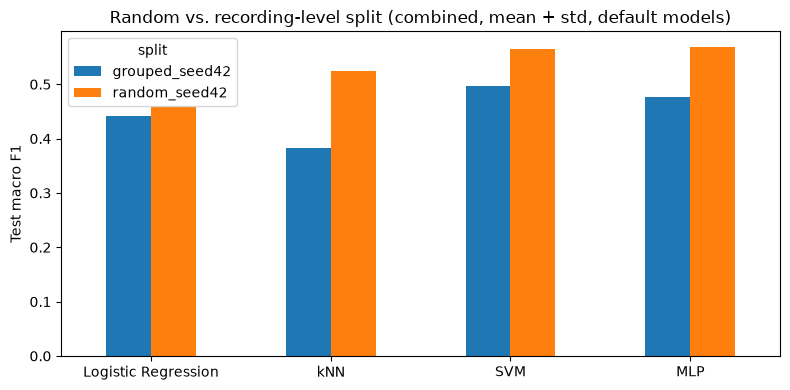

In [3]:
fig, ax = plt.subplots(figsize=(8, 4))
leakage_table.pivot(index="model", columns="split", values="Test macro F1").loc[MODEL_NAMES].plot.bar(ax=ax, rot=0)
ax.set_ylabel("Test macro F1")
ax.set_xlabel("")
ax.set_title("Random vs. recording-level split (combined, mean + std, default models)")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "leakage_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

## 2. Feature study

Tuned SVM, mean + std pooling, validation split. Each row changes one choice relative to "Extended (defaults)" (13 MFCCs, MFCC 0 kept, 2048-sample window). The settings of the final `extended` feature set were chosen from this table by the rule described in `02_training.ipynb`.

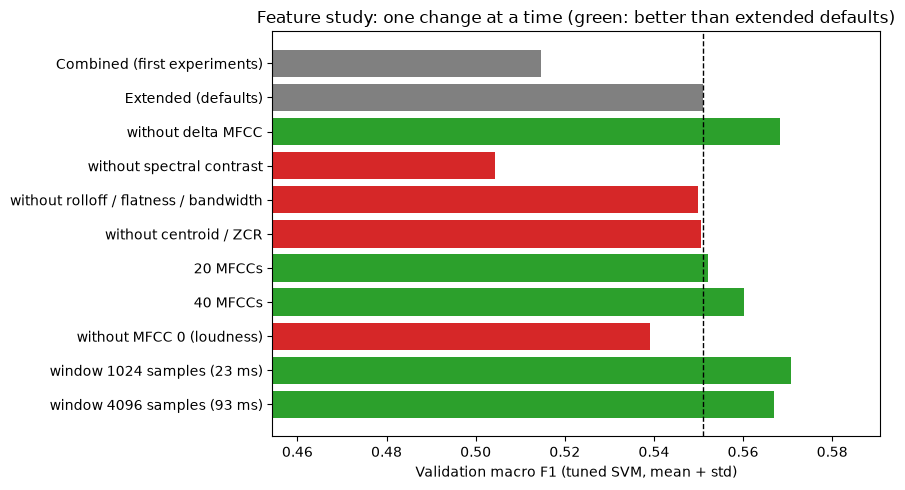

,Variant,dimensions,Val accuracy,Val macro F1,Change vs. extended defaults,params
0,Combined (first experiments),30.0,0.5249,0.5148,-0.0362,"{""C"": 100.0, ""gamma"": 0.003}"
1,Extended (defaults),76.0,0.5596,0.5510,0.0000,"{""C"": 100.0, ""gamma"": ""scale""}"
2,without delta MFCC,50.0,0.5795,0.5684,0.0174,"{""C"": 100.0, ""gamma"": 0.003}"
3,without spectral contrast,62.0,0.5119,0.5044,-0.0466,"{""C"": 10.0, ""gamma"": 0.01}"
4,without rolloff / flatness / bandwidth,70.0,0.5606,0.5499,-0.0010,"{""C"": 10.0, ""gamma"": ""scale""}"
5,without centroid / ZCR,72.0,0.5577,0.5505,-0.0005,"{""C"": 100.0, ""gamma"": 0.01}"
6,20 MFCCs,104.0,0.5616,0.5521,0.0011,"{""C"": 10.0, ""gamma"": 0.003}"
7,40 MFCCs,184.0,0.5716,0.5603,0.0093,"{""C"": 10.0, ""gamma"": ""scale""}"
8,without MFCC 0 (loudness),72.0,0.5467,0.5392,-0.0118,"{""C"": 1.0, ""gamma"": ""scale""}"
9,window 1024 samples (23 ms),76.0,0.5815,0.5707,0.0198,"{""C"": 10.0, ""gamma"": 0.003}"


Chosen extended feature set: {'groups': ['mfcc', 'spectral_centroid', 'zcr', 'spectral_contrast', 'spectral_rolloff', 'spectral_flatness', 'spectral_bandwidth'], 'n_mfcc': 40, 'n_fft': 1024, 'drop_c0': False}


In [4]:
STUDY_LABELS = {
    "study_combined": "Combined (first experiments)",
    "study_extended": "Extended (defaults)",
    "study_no_delta_mfcc": "without delta MFCC",
    "study_no_spectral_contrast": "without spectral contrast",
    "study_no_spectral_shape": "without rolloff / flatness / bandwidth",
    "study_no_centroid_zcr": "without centroid / ZCR",
    "study_n_mfcc_20": "20 MFCCs",
    "study_n_mfcc_40": "40 MFCCs",
    "study_drop_c0": "without MFCC 0 (loudness)",
    "study_n_fft_1024": "window 1024 samples (23 ms)",
    "study_n_fft_4096": "window 4096 samples (93 ms)"
}

study_table = score_models(model_rows(experiment="feature_study"), MODELS_DIR, df, features, split_table, subsets=("val",))
study_table["Variant"] = study_table["feature_set"].map(STUDY_LABELS)
baseline_f1 = study_table.loc[study_table["feature_set"] == "study_extended", "Val macro F1"].iloc[0]
study_table["Change vs. extended defaults"] = study_table["Val macro F1"] - baseline_f1
study_table = study_table[["Variant", "dimensions", "Val accuracy", "Val macro F1", "Change vs. extended defaults", "params"]]
study_table.to_csv(RESULTS_DIR / "feature_study.csv", index=False)

fig, ax = plt.subplots(figsize=(9, 5))
plotted = study_table.iloc[::-1]
colors = ["gray" if variant.startswith(("Combined", "Extended")) else "tab:green" if change > 0 else "tab:red"
          for variant, change in zip(plotted["Variant"], plotted["Change vs. extended defaults"])]
ax.barh(plotted["Variant"], plotted["Val macro F1"], color=colors)
ax.axvline(baseline_f1, color="black", linestyle="--", linewidth=1)
ax.set_xlim(max(0, study_table["Val macro F1"].min() - 0.05), study_table["Val macro F1"].max() + 0.02)
ax.set_xlabel("Validation macro F1 (tuned SVM, mean + std)")
ax.set_title("Feature study: one change at a time (green: better than extended defaults)")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "feature_study.png", dpi=150, bbox_inches="tight")
plt.show()

display(study_table.round(4))
print("Chosen extended feature set:", specs["extended"])

## 3. Feature set × pooling × model, before and after tuning

All scores on the **validation** split of the recording-level split; the test split is not used for any choice.

In [5]:
comparison_scores = score_models(model_rows(experiment="comparison"), MODELS_DIR, df, features, split_table, subsets=("val",))

comparison_table = comparison_scores.pivot_table(
    index=["feature_set", "pooling", "model"], columns="variant", values=["Val accuracy", "Val macro F1"]
)
# e.g. ("Val macro F1", "tuned") -> "Tuned val macro F1"
comparison_table.columns = [f"{variant.capitalize()} {metric[0].lower()}{metric[1:]}" for metric, variant in comparison_table.columns]
comparison_table = comparison_table.reset_index()
comparison_table["Tuning gain (macro F1)"] = comparison_table["Tuned val macro F1"] - comparison_table["Default val macro F1"]
comparison_table = comparison_table.merge(
    comparison_scores.loc[comparison_scores["variant"] == "tuned", ["feature_set", "pooling", "model", "params"]].rename(columns={"params": "Tuned params"}),
    on=["feature_set", "pooling", "model"]
)
comparison_table = readable(comparison_table).sort_values("Tuned val macro F1", ascending=False)
comparison_table.to_csv(RESULTS_DIR / "validation_comparison.csv", index=False)

comparison_table

,feature_set,pooling,model,Default val accuracy,Tuned val accuracy,Default val macro F1,Tuned val macro F1,Tuning gain (macro F1),Tuned params
13,Extended,Mean + Std,MLP,0.532803,0.585487,0.525460,0.583047,0.057587,"{""hidden_dims"": [256, 128], ""dropout"": 0.3, ""w..."
14,Extended,Mean + Std,SVM,0.572565,0.576541,0.558763,0.566584,0.007820,"{""C"": 10.0, ""gamma"": ""scale""}"
12,Extended,Mean + Std,Logistic Regression,0.547714,0.558648,0.541488,0.552747,0.011259,"{""C"": 100.0}"
5,Combined,Mean + Std,MLP,0.494036,0.530815,0.488823,0.523904,0.035082,"{""hidden_dims"": [256, 128], ""dropout"": 0.3, ""w..."
6,Combined,Mean + Std,SVM,0.502982,0.524851,0.497099,0.514759,0.017660,"{""C"": 100.0, ""gamma"": 0.003}"
29,MFCC,Mean + Std,MLP,0.476143,0.511928,0.468211,0.510369,0.042158,"{""hidden_dims"": [256, 128], ""dropout"": 0.3, ""w..."
9,Extended,Mean,MLP,0.471173,0.512922,0.474506,0.509887,0.035381,"{""hidden_dims"": [256, 128], ""dropout"": 0.3, ""w..."
10,Extended,Mean,SVM,0.509940,0.512922,0.499651,0.506513,0.006862,"{""C"": 10.0, ""gamma"": 0.01}"
30,MFCC,Mean + Std,SVM,0.479125,0.490060,0.471587,0.486172,0.014585,"{""C"": 10.0, ""gamma"": 0.01}"
8,Extended,Mean,Logistic Regression,0.482107,0.482107,0.475267,0.475672,0.000405,"{""C"": 100.0}"


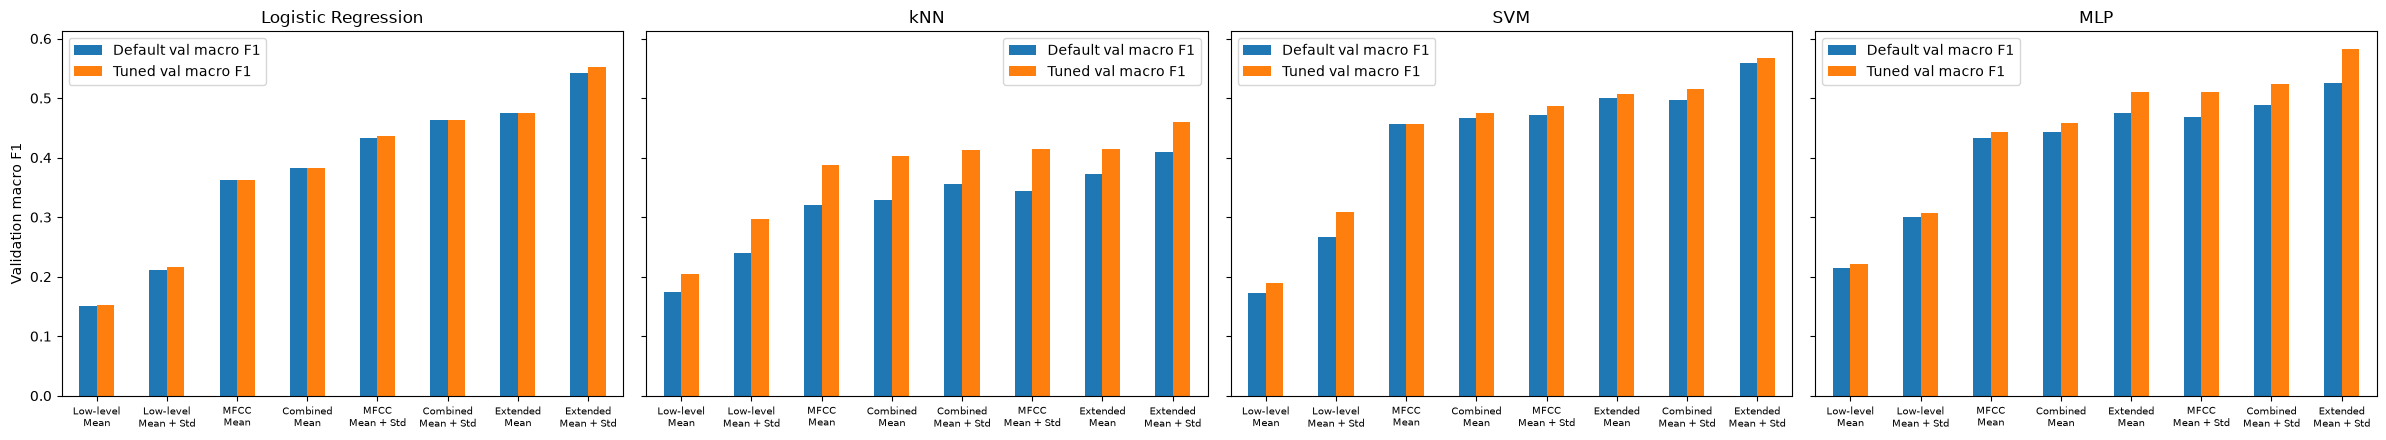

In [6]:
fig, axes = plt.subplots(1, len(MODEL_NAMES), figsize=(6 * len(MODEL_NAMES), 4.5), sharey=True)
for ax, model_name in zip(axes, MODEL_NAMES):
    table = comparison_table[comparison_table["model"] == model_name].copy()
    table["config"] = table["feature_set"] + "\n" + table["pooling"]
    table = table.set_index("config").sort_values("Tuned val macro F1")
    table[["Default val macro F1", "Tuned val macro F1"]].plot.bar(ax=ax, rot=0)
    ax.set_title(model_name)
    ax.set_xlabel("")
    ax.tick_params(axis="x", labelsize=7)
axes[0].set_ylabel("Validation macro F1")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "validation_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

In [7]:
# Grid search results for the best configuration (top 5 settings per model)
for model_name in MODEL_NAMES:
    print(model_name)
    display(pd.read_csv(MODELS_DIR / "tuning" / f"{best_feature_set}_{best_pooling}_{MODEL_SLUGS[model_name]}.csv").head(5))

Logistic Regression


,C,Val accuracy,Val macro F1,Fit seconds
0,100.00,0.558648,0.552747,13.139931
1,10.00,0.556660,0.550165,12.085346
2,0.10,0.553678,0.547764,3.889275
3,1.00,0.547714,0.541488,5.835922
4,0.01,0.520875,0.509540,1.599486


kNN


,n_neighbors,weights,p,Val accuracy,Val macro F1,Fit seconds
0,41,distance,1,0.475149,0.459612,0.001759
1,41,uniform,1,0.474155,0.456250,0.001740
2,11,distance,1,0.461233,0.447697,0.001754
3,21,distance,1,0.462227,0.446971,0.001959
4,21,distance,2,0.463221,0.444018,0.002386


SVM


,C,gamma,Val accuracy,Val macro F1,Fit seconds
0,10.0,scale,0.576541,0.566584,1.678811
1,10.0,0.01,0.575547,0.565780,1.744464
2,10.0,0.003,0.570577,0.563449,1.070525
3,100.0,0.01,0.570577,0.560954,1.647801
4,100.0,scale,0.568588,0.559065,1.675511


MLP


,hidden_dims,dropout,weight_decay,epochs,patience,Val accuracy,Val macro F1,Fit seconds
0,"(256, 128)",0.3,0.0001,300,20,0.585487,0.583047,5.594101
1,"(64, 32)",0.3,0.0001,300,20,0.582505,0.573511,7.704771
2,"(256, 128)",0.3,0.0000,300,20,0.576541,0.569807,5.574365
3,"(64, 32)",0.3,0.0000,300,20,0.577535,0.569218,7.439995
4,"(256, 128)",0.0,0.0000,300,20,0.561630,0.549422,3.940711


## 4. Comparing the models

The four models represent four different ideas of what "learning a classifier" means:

| | Logistic Regression | kNN | SVM (RBF kernel) | MLP |
|---|---|---|---|---|
| **Family** | linear, probabilistic | instance-based (non-parametric) | kernel method | neural network |
| **Decision boundary** | hyperplanes between classes | follows the training points locally; arbitrarily complex | smooth non-linear boundaries, defined by support vectors | non-linear, learned feature combinations in hidden layers |
| **What is learned** | one weight per feature and class | nothing: stores the training set | which training points matter (support vectors) and their weights | weights of all layers, by gradient descent |
| **Key hyperparameters** | C (regularization) | k (smoothness), weighting, distance | C (margin vs. errors), γ (kernel width) | size, dropout, weight decay, early stopping |
| **Training cost** | low | none | grows ~quadratically with the training set | moderate, iterative, needs a validation set |
| **Prediction cost** | very low | high: distance to every training point | grows with the number of support vectors | low |
| **Interpretability** | high: weights per feature | high per prediction (the neighbours can be listed and listened to) | low | low |
| **Sensitivity to feature scaling / irrelevant features** | moderate | very high: every feature counts equally in the distance | high | moderate (can learn to ignore features) |

The analyses below test these differences on this data.

### Decision regions

Each model trained on only the first two principal components of the best feature set (the 2D scores are far below the real ones). The background colour is the predicted instrument; the dots are validation excerpts.

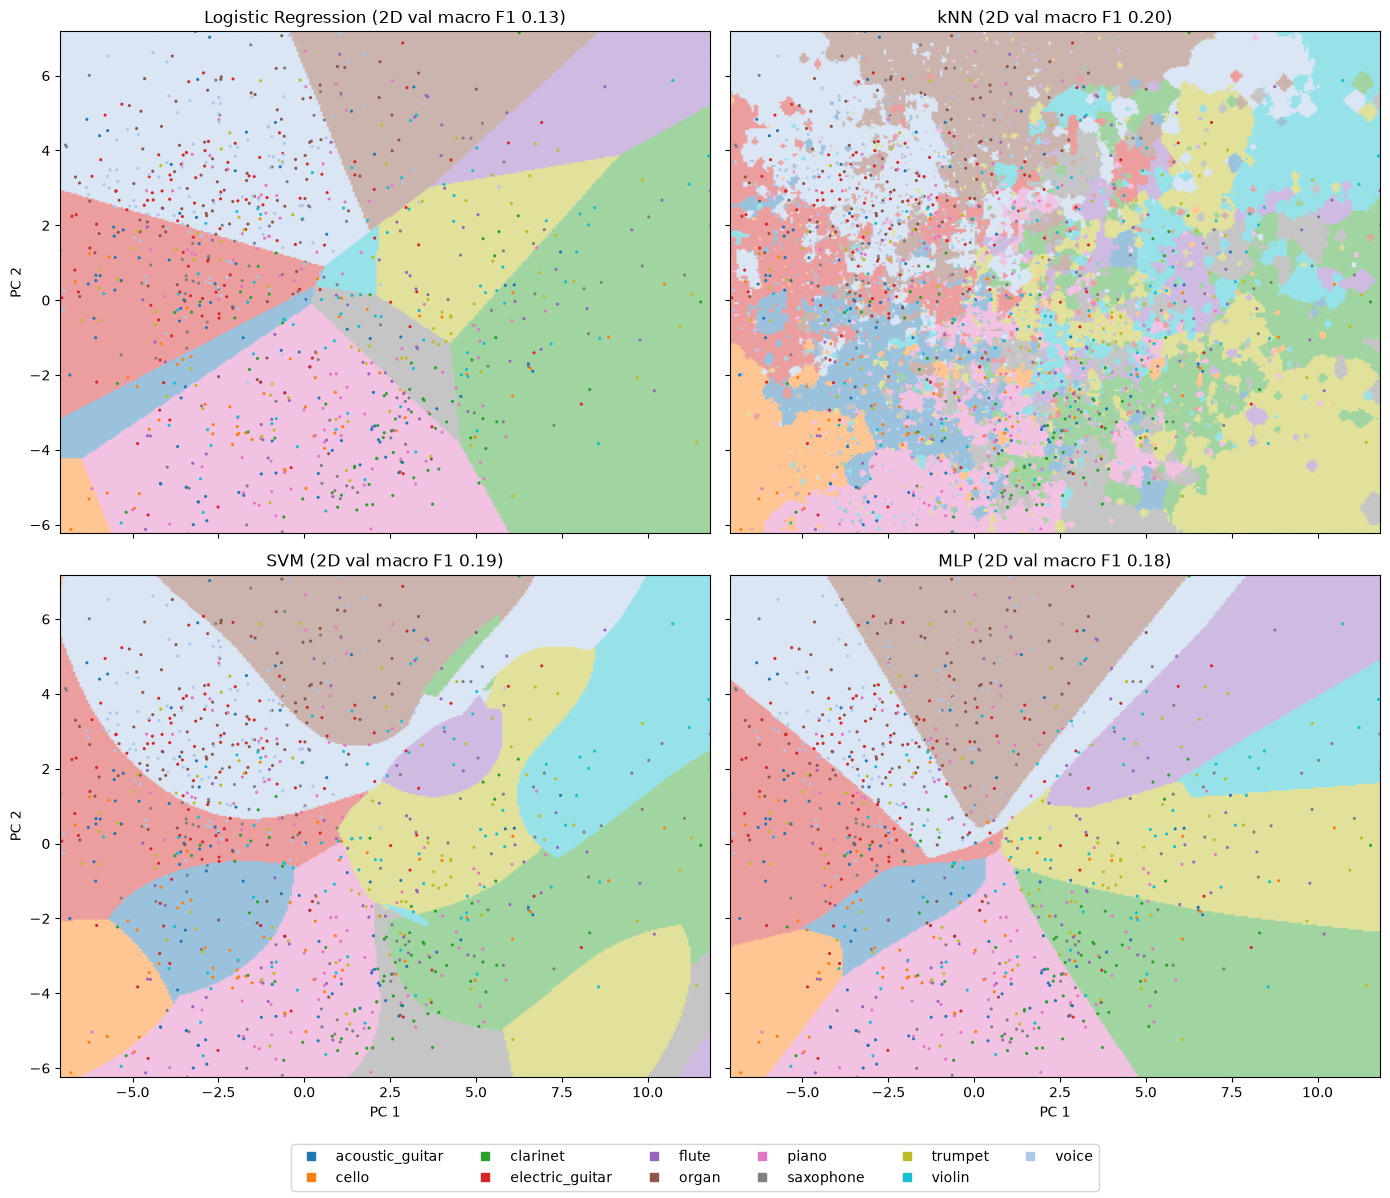

In [8]:
classes = np.array(sorted(df["label"].unique()))
class_colors = ListedColormap([plt.colormaps["tab20"](i) for i in list(range(0, 20, 2)) + [1]][:len(classes)])

illustration_rows = model_rows(experiment="illustration")
first_bundle = load_model(MODELS_DIR, illustration_rows.iloc[0])
val_2d = first_bundle["scaler"].transform(features[best_pooling][best_feature_set][val_df.index])
y_val_index = np.searchsorted(classes, val_df["label"].values)

(x_min, y_min), (x_max, y_max) = np.percentile(val_2d, 1, axis=0), np.percentile(val_2d, 99, axis=0)
grid_x, grid_y = np.meshgrid(np.linspace(x_min, x_max, 300), np.linspace(y_min, y_max, 300))
grid = np.column_stack([grid_x.ravel(), grid_y.ravel()])

fig, axes = plt.subplots(2, 2, figsize=(14, 12), sharex=True, sharey=True)
for ax, (_, row) in zip(axes.flat, illustration_rows.iterrows()):
    model = load_model(MODELS_DIR, row)["model"]
    regions = np.searchsorted(classes, model.predict(grid)).reshape(grid_x.shape)
    val_f1 = evaluate_model(val_df["label"].values, model.predict(val_2d), verbose=False)["macro_f1"]
    ax.imshow(regions, origin="lower", extent=(x_min, x_max, y_min, y_max), cmap=class_colors, vmin=-0.5, vmax=len(classes) - 0.5, alpha=0.45, aspect="auto")
    ax.scatter(val_2d[:, 0], val_2d[:, 1], c=y_val_index, cmap=class_colors, vmin=-0.5, vmax=len(classes) - 0.5, s=5, edgecolors="none")
    ax.set_title(f"{row['model']} (2D val macro F1 {val_f1:.2f})")
    ax.set_xlim(x_min, x_max)
    ax.set_ylim(y_min, y_max)
for ax in axes[1]:
    ax.set_xlabel("PC 1")
for ax in axes[:, 0]:
    ax.set_ylabel("PC 2")
handles = [plt.Line2D([], [], marker="s", linestyle="", color=class_colors(i), label=label) for i, label in enumerate(classes)]
fig.legend(handles=handles, loc="lower center", ncol=6)
fig.tight_layout(rect=(0, 0.05, 1, 1))
fig.savefig(FIGURES_DIR / "decision_regions.png", dpi=150, bbox_inches="tight")
plt.show()

### Learning curves: how much data does each model need?

Validation macro F1 of the tuned models of the best configuration, trained on 10% / 25% / 50% / 100% of the training split.

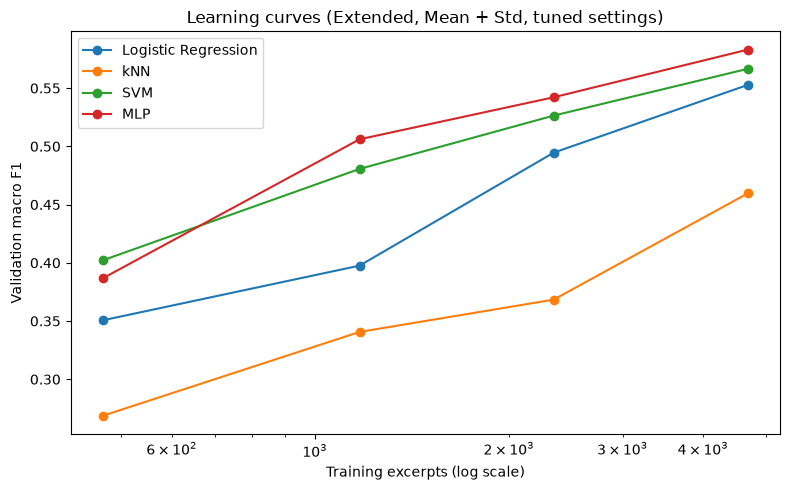

In [9]:
learning_rows = pd.concat([
    model_rows(experiment="learning_curve"),
    model_rows(experiment="comparison", feature_set=best_feature_set, pooling=best_pooling, variant="tuned").assign(train_fraction=1.0, train_size=len(train_df))
])
learning_table = score_models(learning_rows, MODELS_DIR, df, features, split_table, subsets=("val",))
learning_table = learning_table[["model", "train_fraction", "train_size", "fit_seconds", "Val accuracy", "Val macro F1"]].sort_values(["model", "train_size"])
learning_table.to_csv(RESULTS_DIR / "learning_curves.csv", index=False)

fig, ax = plt.subplots(figsize=(8, 5))
for model_name in MODEL_NAMES:
    table = learning_table[learning_table["model"] == model_name]
    ax.plot(table["train_size"], table["Val macro F1"], marker="o", label=model_name)
ax.set_xscale("log")
ax.set_xlabel("Training excerpts (log scale)")
ax.set_ylabel("Validation macro F1")
ax.set_title(f"Learning curves ({best_config_name}, tuned settings)")
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES_DIR / "learning_curves.png", dpi=150, bbox_inches="tight")
plt.show()

### Hyperparameters: bias vs. variance

- **kNN:** small k follows individual training points (low bias, high variance); large k averages over many neighbours (smoother, more bias).
- **SVM:** large C and large γ allow a more complex boundary.

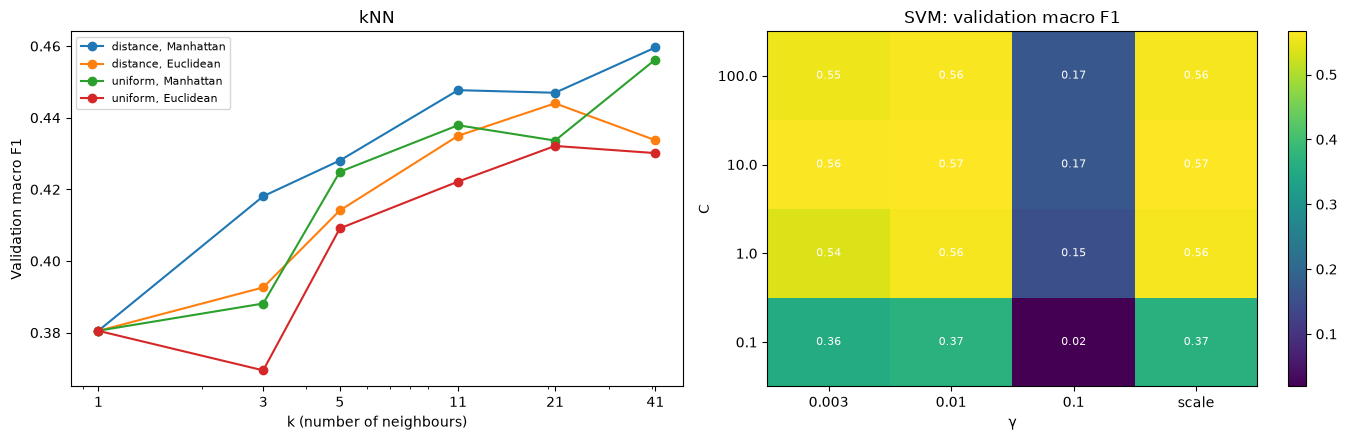

In [10]:
knn_tuning = pd.read_csv(MODELS_DIR / "tuning" / f"{best_feature_set}_{best_pooling}_knn.csv")
svm_tuning = pd.read_csv(MODELS_DIR / "tuning" / f"{best_feature_set}_{best_pooling}_svm.csv")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for (weights, p), table in knn_tuning.groupby(["weights", "p"]):
    table = table.sort_values("n_neighbors")
    axes[0].plot(table["n_neighbors"], table["Val macro F1"], marker="o", label=f"{weights}, {'Euclidean' if p == 2 else 'Manhattan'}")
axes[0].set_xscale("log")
axes[0].set_xticks(sorted(knn_tuning["n_neighbors"].unique()), sorted(knn_tuning["n_neighbors"].unique()))
axes[0].set_xlabel("k (number of neighbours)")
axes[0].set_ylabel("Validation macro F1")
axes[0].set_title("kNN")
axes[0].legend(fontsize=8)

svm_grid = svm_tuning.pivot_table(index="C", columns="gamma", values="Val macro F1")
image = axes[1].imshow(svm_grid, cmap="viridis", aspect="auto", origin="lower")
axes[1].set_xticks(range(svm_grid.shape[1]), svm_grid.columns)
axes[1].set_yticks(range(svm_grid.shape[0]), svm_grid.index)
axes[1].set_xlabel("γ")
axes[1].set_ylabel("C")
axes[1].set_title("SVM: validation macro F1")
for (i, j), value in np.ndenumerate(svm_grid.values):
    axes[1].text(j, i, f"{value:.2f}", ha="center", va="center", color="white", fontsize=8)
fig.colorbar(image, ax=axes[1])
fig.tight_layout()
fig.savefig(FIGURES_DIR / "hyperparameters_knn_svm.png", dpi=150, bbox_inches="tight")
plt.show()

### Cost and size

Training time (from `02_training.ipynb`, final fit with the tuned settings), prediction time per 1000 excerpts (measured here, features already extracted), and the size of the saved model. kNN stores the whole training set; the SVM stores its support vectors.

In [11]:
best_rows = model_rows(experiment="comparison", feature_set=best_feature_set, pooling=best_pooling, variant="tuned")
x_test_best = features[best_pooling][best_feature_set][test_df.index]

cost_rows = []
for _, row in best_rows.iterrows():
    bundle = load_model(MODELS_DIR, row)
    timings = []
    for _ in range(3):
        start = time.perf_counter()
        predict(bundle, x_test_best)
        timings.append(time.perf_counter() - start)
    cost_rows.append({
        "Model": row["model"],
        "Training seconds": row["fit_seconds"],
        "Prediction ms per 1000 excerpts": 1000 * min(timings) / len(x_test_best) * 1000,
        "Saved model size (KB)": (MODELS_DIR / row["path"]).stat().st_size / 1024,
        "Support vectors": getattr(bundle["model"], "n_support_", np.array([np.nan])).sum()
    })

cost_table = pd.DataFrame(cost_rows)
cost_table.to_csv(RESULTS_DIR / "model_cost.csv", index=False)
cost_table.round(3)

,Model,Training seconds,Prediction ms per 1000 excerpts,Saved model size (KB),Support vectors
0,Logistic Regression,13.140,1.027,12.923,NaN
1,kNN,0.002,90.258,3853.360,NaN
2,SVM,1.679,368.558,4166.110,4277.0
3,MLP,5.594,2.833,247.095,NaN


### Which features does each model use?

Permutation importance on the validation split: the drop in macro F1 when one feature group is shuffled across excerpts. A large drop means the model relies on that group. kNN cannot learn to ignore features, so it can be hurt by uninformative ones.

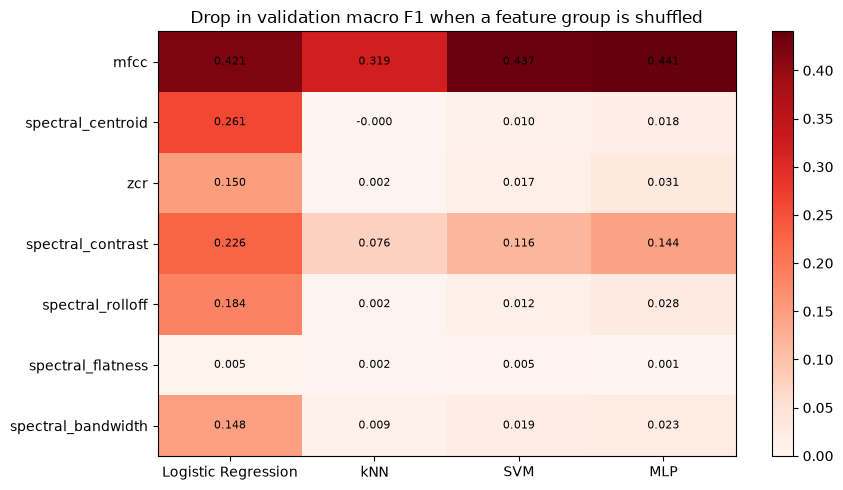

In [12]:
spec = specs[best_feature_set]
pooled_best = build_pooled_features(df, n_fft=spec["n_fft"], hop_length=HOP_LENGTH, cache_path=CACHE_DIR / f"train_nfft{spec['n_fft']}.npz")
_, column_names = assemble_features(pooled_best, spec, best_pooling, return_names=True)
column_groups = [group for group, _ in column_names]
x_val_best = features[best_pooling][best_feature_set][val_df.index]

importance = {}
for _, row in best_rows.iterrows():
    bundle = load_model(MODELS_DIR, row)
    table = group_permutation_importance(lambda x: predict(bundle, x), x_val_best, val_df["label"].values, column_groups, n_repeats=5, seed=SEED)
    importance[row["model"]] = table.set_index("Group")["Macro F1 drop"]

importance = pd.DataFrame(importance)[MODEL_NAMES]
importance.to_csv(RESULTS_DIR / "feature_group_importance.csv")

fig, ax = plt.subplots(figsize=(9, 0.5 * len(importance) + 1.5))
image = ax.imshow(importance, cmap="Reds", aspect="auto")
ax.set_xticks(range(len(MODEL_NAMES)), MODEL_NAMES)
ax.set_yticks(range(len(importance)), importance.index)
for (i, j), value in np.ndenumerate(importance.values):
    ax.text(j, i, f"{value:.3f}", ha="center", va="center", fontsize=8)
ax.set_title("Drop in validation macro F1 when a feature group is shuffled")
fig.colorbar(image, ax=ax)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "feature_group_importance.png", dpi=150, bbox_inches="tight")
plt.show()

### Discussion: comparing and contrasting the models

*To be completed with the numbers above.* Structure:

- **Linear vs. non-linear.** If the SVM, MLP and kNN beat Logistic Regression clearly, the instrument classes are not linearly separable in this feature space, as the PCA plot in `01_data_exploration.ipynb` suggests. The decision regions show *how* they differ: straight boundaries for Logistic Regression, smooth curved ones for the SVM, irregular local ones for kNN.
- **Local vs. global.** kNN decides from a few similar excerpts, so it can capture small clusters (one recording style of an instrument) but is sensitive to noise and to irrelevant features. Compare its k curve (best k, uniform vs. distance weighting) and its feature importance with the other models.
- **Capacity vs. data size.** Read the learning curves:
  - Which model is best with little data?
  - Which keeps improving at 100%, i.e. would profit from more data?
  - Does the MLP need more data than the SVM to catch up? With ~4.7k training excerpts, kernel methods are usually hard to beat.
- **Cost.**
  - Training: kNN does no training, but it is the slowest to predict and the largest to store (it stores the training set).
  - The SVM's cost depends on its number of support vectors. Many support vectors means many excerpts lie near a boundary, i.e. the classes overlap.
  - The MLP is cheap at prediction time.
- **Interpretability.** Logistic Regression's weights and kNN's neighbours can be inspected. For the SVM and MLP only indirect tools (like the permutation importance above) are available.
- **Pooled features vs. spectrograms.** All four models see the same fixed-length pooled vectors, so none can model temporal structure beyond what mean, std and delta statistics keep. A convolutional network on log-mel spectrograms (state of the art for IRMAS, e.g. Han et al. 2017) learns its features from the time-frequency representation instead, at the price of much more data and compute.

## 5. Best configuration on the test split

The tuned models of the best configuration on validation, evaluated once on the test split of the recording-level split.

In [13]:
y_test = test_df["label"].values

test_models = {}
test_results = {}
for _, row in best_rows.iterrows():
    model_name = row["model"]
    test_models[model_name] = load_model(MODELS_DIR, row)
    print(f"\n{best_config_name} - {model_name}")
    test_results[model_name] = evaluate_model(y_test, predict(test_models[model_name], x_test_best))

test_results_table = pd.DataFrame([
    {"Configuration": best_config_name, "Model": model_name, "Test accuracy": results["accuracy"], "Test macro F1": results["macro_f1"]}
    for model_name, results in test_results.items()
])
test_results_table.to_csv(RESULTS_DIR / "test_results.csv", index=False)

test_results_table


Extended, Mean + Std - Logistic Regression
Accuracy: 0.5164
Macro F1: 0.5112

                 precision    recall  f1-score   support

acoustic_guitar       0.52      0.60      0.56        95
          cello       0.49      0.62      0.55        58
       clarinet       0.51      0.40      0.45        75
electric_guitar       0.46      0.49      0.47       117
          flute       0.51      0.46      0.48        69
          organ       0.54      0.63      0.58        99
          piano       0.45      0.46      0.45       108
      saxophone       0.47      0.36      0.41        95
        trumpet       0.50      0.51      0.51        88
         violin       0.51      0.48      0.49        86
          voice       0.68      0.65      0.67       117

       accuracy                           0.52      1007
      macro avg       0.51      0.51      0.51      1007
   weighted avg       0.52      0.52      0.51      1007


Extended, Mean + Std - kNN
Accuracy: 0.4290
Macro F1: 0.4155



,Configuration,Model,Test accuracy,Test macro F1
0,"Extended, Mean + Std",Logistic Regression,0.516385,0.511204
1,"Extended, Mean + Std",kNN,0.428997,0.415532
2,"Extended, Mean + Std",SVM,0.555114,0.548941
3,"Extended, Mean + Std",MLP,0.541212,0.539890


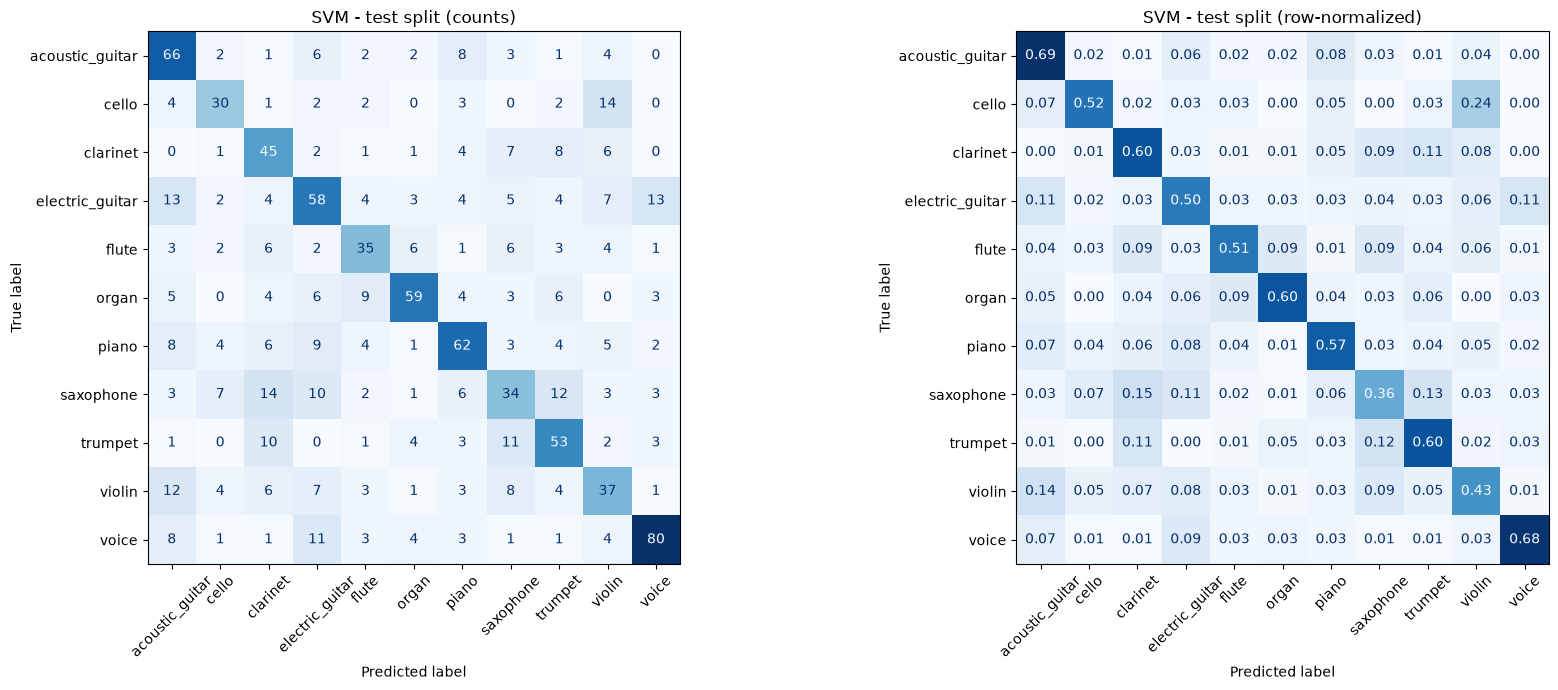

In [14]:
best_model_name = test_results_table.loc[test_results_table["Test macro F1"].idxmax(), "Model"]
best_test_results = test_results[best_model_name]

fig, axes = plt.subplots(1, 2, figsize=(18, 7))
plot_confusion_matrix(best_test_results, title=f"{best_model_name} - test split (counts)", ax=axes[0])
plot_confusion_matrix(best_test_results, normalize=True, title=f"{best_model_name} - test split (row-normalized)", ax=axes[1])
fig.tight_layout()
fig.savefig(FIGURES_DIR / "confusion_matrix_test.png", dpi=150, bbox_inches="tight")
plt.show()

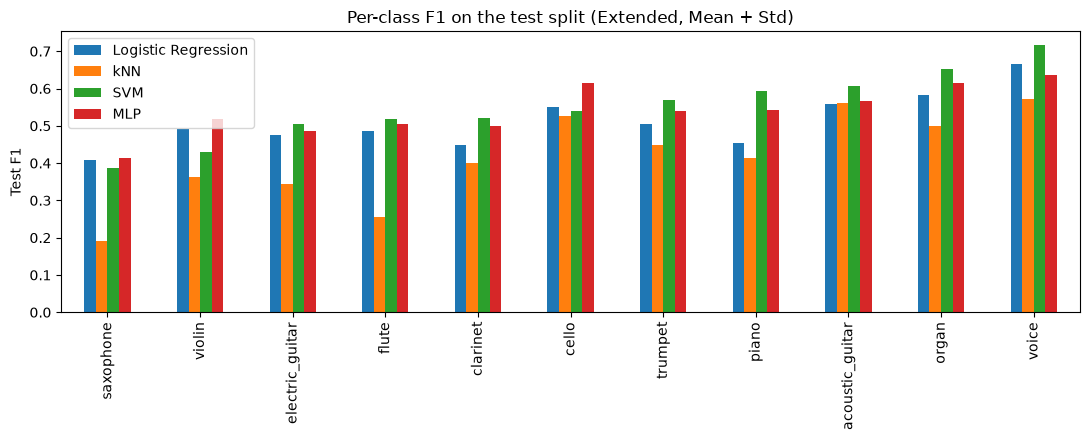

Logistic Regression                     kNN                \
                          Precision Recall     F1 Precision Recall     F1   
saxophone                     0.472  0.358  0.407     0.238  0.158  0.190   
violin                        0.506  0.477  0.491     0.429  0.314  0.362   
electric_guitar               0.463  0.487  0.475     0.310  0.385  0.344   
flute                         0.508  0.464  0.485     0.647  0.159  0.256   
clarinet                      0.508  0.400  0.448     0.450  0.360  0.400   
cello                         0.493  0.621  0.550     0.517  0.534  0.525   
trumpet                       0.500  0.511  0.506     0.620  0.352  0.449   
piano                         0.446  0.463  0.455     0.320  0.583  0.413   
acoustic_guitar               0.523  0.600  0.559     0.533  0.589  0.560   
organ                         0.544  0.626  0.582     0.571  0.444  0.500   
voice                         0.685  0.650  0.667     0.482  0.701  0.571   

                      SVM                     MLP               Support  
                Precision Recall     F1 Precision Recall     F1          
saxophone           0.420  0.358  0.386     0.456  0.379  0.414      95  
violin              0.430  0.430  0.430     0.524  0.512  0.518      86  
electric_guitar     0.513  0.496  0.504     0.468  0.504  0.486     117  
flute               0.530  0.507  0.519     0.552  0.464  0.504      69  
clarinet            0.459  0.600  0.520     0.522  0.480  0.500      75  
cello               0.566  0.517  0.541     0.610  0.621  0.615      58  
trumpet             0.541  0.602  0.570     0.606  0.489  0.541      88  
piano               0.614  0.574  0.593     0.489  0.611  0.543     108  
acoustic_guitar     0.537  0.695  0.606     0.508  0.642  0.567      95  
organ               0.720  0.596  0.652     0.587  0.646  0.615      99  
voice               0.755  0.684  0.717     0.701  0.581  0.636     117

In [15]:
# Per-class metrics of all models side by side
per_class = pd.concat({model_name: per_class_metrics(results)[["Precision", "Recall", "F1"]] for model_name, results in test_results.items()}, axis=1)
per_class["Support"] = per_class_metrics(best_test_results)["Support"]
per_class = per_class.sort_values((best_model_name, "F1"))
per_class.to_csv(RESULTS_DIR / "per_class_test.csv")

fig, ax = plt.subplots(figsize=(11, 4.5))
per_class.xs("F1", axis=1, level=1).plot.bar(ax=ax)
ax.set_ylabel("Test F1")
ax.set_title(f"Per-class F1 on the test split ({best_config_name})")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "per_class_f1_test.png", dpi=150, bbox_inches="tight")
plt.show()

per_class.round(3)

In [16]:
# Most frequent confusions and how many errors stay within an instrument family
confusions = top_confusions(best_test_results, k=10)
confusions.to_csv(RESULTS_DIR / "top_confusions_test.csv", index=False)
display(confusions)

family_errors = family_error_share(best_test_results)
print(f"Errors within the same instrument family: {family_errors['within_family_share']:.1%} "
      f"(would be {family_errors['chance_within_family_share']:.1%} if errors were spread uniformly)")

,True,Predicted,Count,Share of true class,Same family
0,cello,violin,14,0.241379,True
1,saxophone,clarinet,14,0.147368,True
2,electric_guitar,voice,13,0.111111,False
3,electric_guitar,acoustic_guitar,13,0.111111,True
4,saxophone,trumpet,12,0.126316,False
5,violin,acoustic_guitar,12,0.139535,False
6,trumpet,saxophone,11,0.125000,False
7,voice,electric_guitar,11,0.094017,False
8,saxophone,electric_guitar,10,0.105263,False
9,trumpet,clarinet,10,0.113636,False


Errors within the same instrument family: 17.4% (would be 10.9% if errors were spread uniformly)


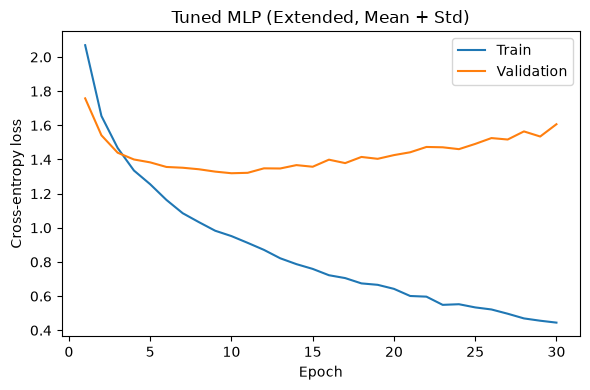

In [17]:
# Training curves of the tuned MLP (early stopping restores the epoch with the lowest validation loss)
mlp = test_models["MLP"]["model"]
plot_loss_curves(mlp.train_losses_, mlp.val_losses_, title=f"Tuned MLP ({best_config_name})", save_path=FIGURES_DIR / "mlp_loss_curves.png")
plt.show()

### Discussion of the errors

*To be written after running, using the tables above.* Points to cover:

- **Which classes are hardest** (lowest F1), and whether that matches their number of training excerpts (cello and flute are the smallest classes).
- **The most frequent confusions.** Are they within an instrument family, as the "Same family" column and the within-family share suggest? The families are strings (violin/cello), woodwinds (clarinet/flute/saxophone), keyboards (piano/organ) and guitars (acoustic/electric). Those instruments have similar spectral envelopes, which is exactly what MFCCs summarize.
- **Confusions across families,** e.g. with voice or electric guitar. These are often a sign that the excerpt is dominated by accompaniment or production style (distortion, reverb) rather than by the instrument; compare with the genre/drums plot in `01_data_exploration.ipynb`.
- **Did the extended features help where expected?** For example, did delta MFCCs reduce piano/organ confusion (percussive vs. sustained)? Compare with the combined feature set's confusions if needed.

## 6. Variance over recording-level splits

The best configuration, tuned and trained on 5 other recording-level splits, each evaluated on its own test split.

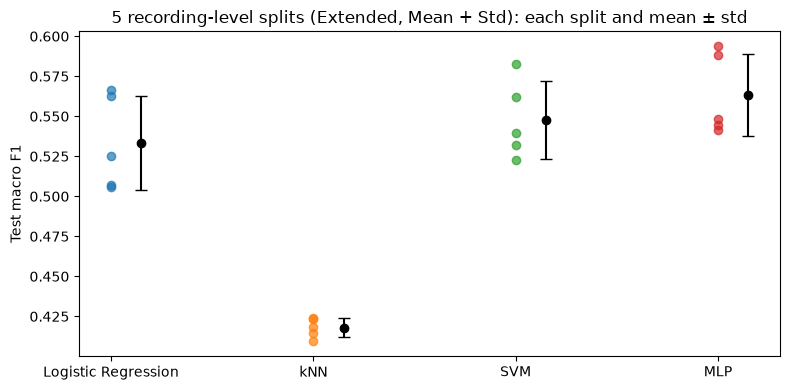

Test accuracy         Test macro F1        
                             mean     std          mean     std
model                                                          
Logistic Regression        0.5408  0.0288        0.5333  0.0294
kNN                        0.4403  0.0100        0.4179  0.0060
SVM                        0.5577  0.0256        0.5477  0.0243
MLP                        0.5698  0.0272        0.5634  0.0255

In [18]:
repeated_results = score_models(model_rows(experiment="repeated"), MODELS_DIR, df, features, split_table, subsets=("test",))
repeated_results.to_csv(RESULTS_DIR / "repeated_splits.csv", index=False)

repeated_summary = summarize_repeated(repeated_results)
repeated_summary.to_csv(RESULTS_DIR / "repeated_splits_summary.csv")

fig, ax = plt.subplots(figsize=(8, 4))
for i, model_name in enumerate(MODEL_NAMES):
    scores = repeated_results.loc[repeated_results["model"] == model_name, "Test macro F1"]
    ax.scatter(np.full(len(scores), i), scores, alpha=0.7)
    ax.errorbar(i + 0.15, scores.mean(), yerr=scores.std(), fmt="o", color="black", capsize=4)
ax.set_xticks(range(len(MODEL_NAMES)), MODEL_NAMES)
ax.set_ylabel("Test macro F1")
ax.set_title(f"5 recording-level splits ({best_config_name}): each split and mean ± std")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "repeated_splits.png", dpi=150, bbox_inches="tight")
plt.show()

repeated_summary.round(4)

## 7. Official IRMAS test set

- **The data:** 5-20 s excerpts from recordings not in the training data, annotated with **all** predominant instruments (multi-label).
- **Prediction:** each excerpt is cut into 3 s windows (1.5 s hop) and the class probabilities of its windows are averaged. An instrument is predicted when its averaged probability is at least `threshold × the highest one`, so the top instrument is always predicted.
- **Threshold-dependent metrics:** micro and macro F1, the metrics of Bosch et al. 2012 and Han et al. 2017, reported over a range of thresholds.
- **Threshold-free metrics:**
  - *top-1 precision:* is the top-ranked instrument annotated?
  - label ranking average precision;
  - macro average precision.

Picking the threshold from this same curve is optimistic, so report the result at the threshold fixed in advance (0.5) as the main number.

Skipped if the test parts are not in `data/`.

In [19]:
official_df = load_test_dataset(official_test_dirs())
print("Excerpts:", len(official_df))

if len(official_df):
    spec = specs[best_feature_set]
    window_pooled, window_file_index = build_window_pooled_features(
        official_df, window_seconds=WINDOW_SECONDS, hop_seconds=HOP_SECONDS, n_fft=spec["n_fft"], hop_length=HOP_LENGTH,
        cache_path=CACHE_DIR / f"official_test_windows_nfft{spec['n_fft']}.npz"
    )
    windows = assemble_features(window_pooled, spec, best_pooling)
    print("Windows:", windows.shape)
    
    # Tuned models from the comparison; the SVM refit with probability estimates
    official_models = {
        model_name: load_model(MODELS_DIR, model_rows(experiment="official", model="SVM").iloc[0]) if model_name == "SVM" else test_models[model_name]
        for model_name in MODEL_NAMES
    }
    
    official_summaries = []
    official_threshold_tables = []
    for model_name, bundle in official_models.items():
        clip_scores = aggregate_window_probabilities(predict_proba(bundle, windows), window_file_index, len(official_df))
        summary, threshold_table = evaluate_multilabel(official_df["labels"], clip_scores, classes=list(bundle["model"].classes_))
        official_summaries.append({"Model": model_name, **summary})
        official_threshold_tables.append(threshold_table.assign(Model=model_name))
    
    official_summary = pd.DataFrame(official_summaries)
    official_thresholds = pd.concat(official_threshold_tables, ignore_index=True)
    official_summary.to_csv(RESULTS_DIR / "official_test_summary.csv", index=False)
    official_thresholds.to_csv(RESULTS_DIR / "official_test_thresholds.csv", index=False)
    
    display(official_summary)
    display(official_thresholds[np.isclose(official_thresholds["Threshold"], 0.5)])

Excerpts: 2874
Windows: (28377, 104)


,Model,Top-1 precision,LRAP,Macro AP,True labels per clip
0,Logistic Regression,0.607864,0.658134,0.384611,1.710856
1,kNN,0.561935,0.654592,0.348258,1.710856
2,SVM,0.601253,0.658390,0.373168,1.710856
3,MLP,0.636047,0.666872,0.430855,1.710856


,Threshold,Micro F1,Macro F1,Micro precision,Micro recall,Labels per clip,Model
4,0.5,0.477343,0.385150,0.485786,0.469189,1.652401,Logistic Regression
13,0.5,0.477363,0.378051,0.401976,0.587553,2.500696,kNN
22,0.5,0.481854,0.388888,0.420391,0.564369,2.296799,SVM
31,0.5,0.497627,0.411861,0.494184,0.501119,1.734864,MLP


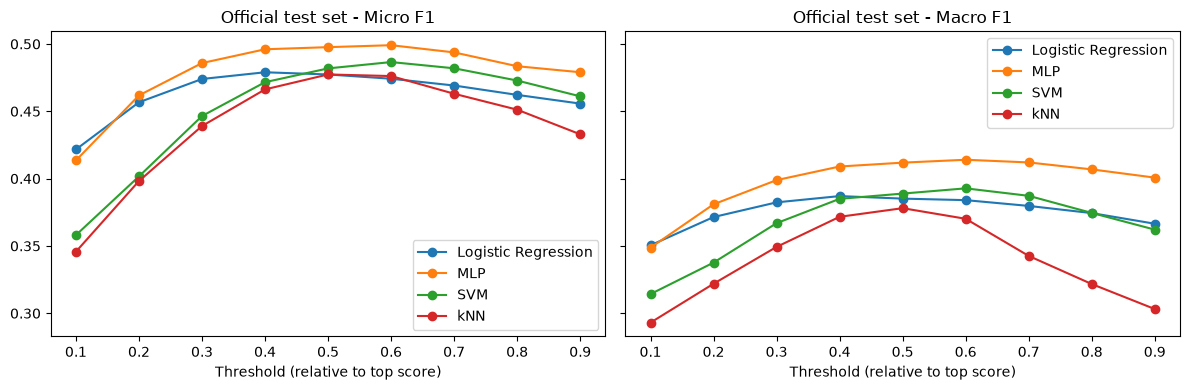

In [20]:
if len(official_df):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
    for model_name, table in official_thresholds.groupby("Model"):
        axes[0].plot(table["Threshold"], table["Micro F1"], marker="o", label=model_name)
        axes[1].plot(table["Threshold"], table["Macro F1"], marker="o", label=model_name)
    for ax, metric in zip(axes, ["Micro F1", "Macro F1"]):
        ax.set_xlabel("Threshold (relative to top score)")
        ax.set_title(f"Official test set - {metric}")
        ax.legend()
    fig.tight_layout()
    fig.savefig(FIGURES_DIR / "official_test_thresholds.png", dpi=150, bbox_inches="tight")
    plt.show()

## 8. Summary

One row per model for the best configuration: validation (used for selection), test split, mean ± std over the 5 extra splits, cost and, if available, the official test set at threshold 0.5.

In [21]:
summary = comparison_table[(comparison_table["feature_set"] == FEATURE_SET_NAMES[best_feature_set])
                           & (comparison_table["pooling"] == POOLING_NAMES[best_pooling])]
summary = summary.set_index("model").loc[MODEL_NAMES, ["Default val macro F1", "Tuned val macro F1"]]
summary["Test macro F1"] = test_results_table.set_index("Model")["Test macro F1"]
summary["Repeated test macro F1 (mean)"] = repeated_summary[("Test macro F1", "mean")]
summary["Repeated test macro F1 (std)"] = repeated_summary[("Test macro F1", "std")]
summary["Prediction ms per 1000 excerpts"] = cost_table.set_index("Model")["Prediction ms per 1000 excerpts"]

if len(official_df):
    at_half = official_thresholds[np.isclose(official_thresholds["Threshold"], 0.5)].set_index("Model")
    summary["Official micro F1 @0.5"] = at_half["Micro F1"]
    summary["Official macro F1 @0.5"] = at_half["Macro F1"]
    summary["Official LRAP"] = official_summary.set_index("Model")["LRAP"]

summary.to_csv(RESULTS_DIR / "summary.csv")
summary.round(3)

,Default val macro F1,Tuned val macro F1,Test macro F1,Repeated test macro F1 (mean),Repeated test macro F1 (std),Prediction ms per 1000 excerpts,Official micro F1 @0.5,Official macro F1 @0.5,Official LRAP
model,,,,,,,,,
Logistic Regression,0.541,0.553,0.511,0.533,0.029,1.027,0.477,0.385,0.658
kNN,0.409,0.460,0.416,0.418,0.006,90.258,0.477,0.378,0.655
SVM,0.559,0.567,0.549,0.548,0.024,368.558,0.482,0.389,0.658
MLP,0.525,0.583,0.540,0.563,0.025,2.833,0.498,0.412,0.667
